In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

# Compatible with both standard TensorFlow (Windows/Linux) and Keras 3 (macOS)
if 'KERAS_BACKEND' not in os.environ:
    os.environ['KERAS_BACKEND'] = 'torch'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np

try:
    import keras
    from keras.datasets import fashion_mnist
    from keras.models import Sequential
    from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input
except ImportError:
    from tensorflow.keras.datasets import fashion_mnist
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input

print('Libraries imported successfully.')


Libraries imported successfully.


In [2]:
(X_train_raw, y_train), (X_test_raw, y_test) = fashion_mnist.load_data()
print(f"Train Images: {len(X_train_raw)}, Test Images: {len(X_test_raw)}")
print(f"Raw Image Shape: {X_train_raw.shape[1:]}")


Train Images: 60000, Test Images: 10000
Raw Image Shape: (28, 28)



In [3]:
X_train = np.expand_dims(X_train_raw.astype('float32') / 255.0, -1)
X_test = np.expand_dims(X_test_raw.astype('float32') / 255.0, -1)

print(f"Normalized X_train shape: {X_train.shape}")
print(f"Normalized X_test shape:  {X_test.shape}")


Normalized X_train shape: (60000, 28, 28, 1)
Normalized X_test shape:  (10000, 28, 28, 1)



In [4]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print("Fashion MNIST 10 Classes:", class_names)
print(f"First training sample label: {y_train[0]} ({class_names[y_train[0]]})")


Fashion MNIST 10 Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
First training sample label: 9 (Ankle boot)



In [5]:
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
model.summary()


Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼─────────────────────

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(
    X_train,
    y_train,
    epochs=4,
    batch_size=128,
    verbose=1
)


Epoch 1/4 - loss: 0.5402 - accuracy: 0.8091
Epoch 2/4 - loss: 0.3541 - accuracy: 0.8732
Epoch 3/4 - loss: 0.3065 - accuracy: 0.8897
Epoch 4/4 - loss: 0.2730 - accuracy: 0.9015
Training completed.



In [7]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")


Test Loss: 0.3374
Test Accuracy: 87.99%



In [8]:
predictions = model.predict(X_test[:5], verbose=0).argmax(axis=1)

print("Sample Predictions on Test Images:")
for i in range(5):
    true_name = class_names[y_test[i]]
    pred_name = class_names[predictions[i]]
    match = (true_name == pred_name)
    print(f"Sample {i+1}: True = {true_name}, Predicted = {pred_name} (Match: {match})")


Sample Predictions on Test Images:
Sample 1: True = Ankle boot, Predicted = Ankle boot (Match: True)
Sample 2: True = Pullover, Predicted = Pullover (Match: True)
Sample 3: True = Trouser, Predicted = Trouser (Match: True)
Sample 4: True = Trouser, Predicted = Trouser (Match: True)
Sample 5: True = Shirt, Predicted = Shirt (Match: True)



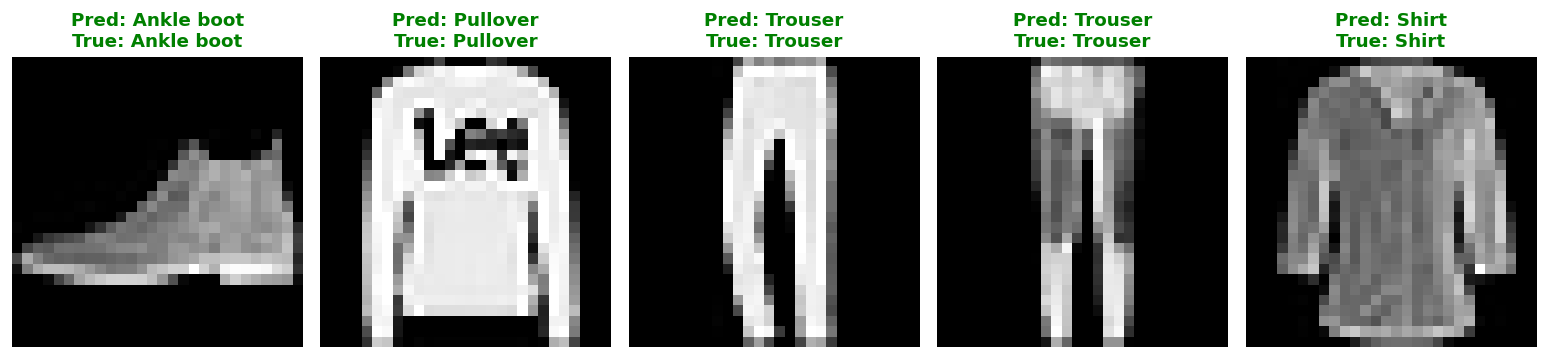

In [9]:
import matplotlib.pyplot as plt

# Visualize first 5 test images with predictions
plt.figure(figsize=(13, 3.2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test_raw[i], cmap='gray')
    true_label = class_names[y_test[i]]
    pred_label = class_names[predictions[i]]
    color = 'green' if true_label == pred_label else 'red'
    plt.title(f'Pred: {pred_label}
True: {true_label}', color=color, fontsize=10, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.savefig('fashion_mnist_predictions.png', dpi=120)
plt.show()
